# Key Differences/Advantages of BQML to Keep in Mind:
1. **No Manual Scaling**: BQML automatically standardizes numerical features (like StandardScaler in Python).
2. **No Manual One-Hot Encoding**: BQML automatically detects string columns (like ocean_proximity) and handles categorical encoding for you.
3. **Built-in Splits**: BQML handles the 80/20 train/test split automatically.

# BQML Linear Regression Model Code:-

```sql
-- Create a schema/dataset in the US region
CREATE SCHEMA IF NOT EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox`
OPTIONS(
  location = 'US'
);

-- Create a cleansed physical training table
CREATE OR REPLACE TABLE `gcp-aiml-sandbox-rahuld-1234.student_sandbox.cleaned_california_housing` AS
WITH median_calc AS (
  -- Calculate the median (50th percentile) of total_bedrooms
  SELECT APPROX_QUANTILES(total_bedrooms, 2)[OFFSET(1)] AS median_bedrooms
  FROM `gcp-aiml-sandbox-rahuld-1234.student_sandbox.raw_california_housing`
)
SELECT
  longitude,
  latitude,
  housing_median_age,
  total_rooms,
  -- Step 4 in Python: Fill missing values with median
  COALESCE(total_bedrooms, (SELECT median_bedrooms FROM median_calc)) AS total_bedrooms,
  population,
  households,
  median_income,
  ocean_proximity, -- BigQuery will auto-detect this as categorical (one-hot encode)
  median_house_value
FROM
  `gcp-aiml-sandbox-rahuld-1234.student_sandbox.raw_california_housing`;

-- Train the BQML Linear Regression model
CREATE OR REPLACE MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.housing_price_model`
OPTIONS (
  model_type = 'linear_reg',
  input_label_cols = ['median_house_value'],
  
  -- Step 5 in Python: Split into 80% train and 20% test
  data_split_method = 'RANDOM',
  data_split_eval_fraction = 0.2,
  
  -- Optional: BQML automatically performs L2 (Ridge) or L1 (Lasso) regularization if specified
  l2_reg = 10.0 -- Similar to Alpha=10 in your Step 10 Ridge regression
) AS
SELECT
  longitude,
  latitude,
  housing_median_age,
  total_rooms,
  total_bedrooms,
  population,
  households,
  median_income,
  ocean_proximity,
  median_house_value
FROM
  `gcp-aiml-sandbox-rahuld-1234.student_sandbox.cleaned_california_housing`;

-- Evaluate the trained model
SELECT
  *
FROM
  ML.EVALUATE(MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.housing_price_model`);


-- View weights/coefficients for each feature (like model.coef_ and model.intercept_ in Python)
SELECT
  processed_input,
  weight,
  category_weights
FROM
  ML.WEIGHTS(MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.housing_price_model`)
ORDER BY 
  ABS(weight) DESC;


-- Generate price predictions for some unseen houses
SELECT
  predicted_median_house_value,
  longitude,
  latitude,
  housing_median_age,
  total_rooms,
  total_bedrooms,
  population,
  households,
  median_income,
  ocean_proximity
FROM
  ML.PREDICT(
    MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.housing_price_model`,
    (
      -- Constructing unseen houses to test
      SELECT 
        -122.23 AS longitude, 37.88 AS latitude, 41.0 AS housing_median_age, 
        880.0 AS total_rooms, 129.0 AS total_bedrooms, 322.0 AS population, 
        126.0 AS households, 8.3 AS median_income, 'NEAR BAY' AS ocean_proximity
      UNION ALL
      SELECT 
        -118.25 AS longitude, 34.05 AS latitude, 20.0 AS housing_median_age, 
        1500.0 AS total_rooms, 350.0 AS total_bedrooms, 1200.0 AS population, 
        310.0 AS households, 3.5 AS median_income, 'INLAND' AS ocean_proximity
    )
  );

-- Clean up all created resources
DROP MODEL IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox.housing_price_model`;
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox.cleaned_california_housing`;
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox.raw_california_housing`;
DROP SCHEMA IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox` CASCADE;
```

# Step-by-Step BigQuery SQL Code:-
- **Step 1**: Create the Schema (Dataset) -> Run this to set up your environment in your project.
```sql
-- Create a schema/dataset in the US region
CREATE SCHEMA IF NOT EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox`
OPTIONS(
  location = 'US'
);

```
---
- **Step 2**: Cleanse the Data (Impute Missing Values) -> In Python, you filled missing total_bedrooms with the median. In SQL, we calculate the median using APPROX_QUANTILES and create a clean table for training.
```sql
-- Create a cleansed physical training table
CREATE OR REPLACE TABLE `gcp-aiml-sandbox-rahuld-1234.student_sandbox.cleaned_california_housing` AS
WITH median_calc AS (
  -- Calculate the median (50th percentile) of total_bedrooms
  SELECT APPROX_QUANTILES(total_bedrooms, 2)[OFFSET(1)] AS median_bedrooms
  FROM `gcp-aiml-sandbox-rahuld-1234.student_sandbox.raw_california_housing`
)
SELECT
  longitude,
  latitude,
  housing_median_age,
  total_rooms,
  -- Step 4 in Python: Fill missing values with median
  COALESCE(total_bedrooms, (SELECT median_bedrooms FROM median_calc)) AS total_bedrooms,
  population,
  households,
  median_income,
  ocean_proximity, -- BigQuery will auto-detect this as categorical (one-hot encode)
  median_house_value
FROM
  `gcp-aiml-sandbox-rahuld-1234.student_sandbox.raw_california_housing`;
```
---

- **Step 3**: Train the Model (Linear Regression) -> BQML handles the split, scaling, and training in one command.
```sql
-- Train the BQML Linear Regression model
CREATE OR REPLACE MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.housing_price_model`
OPTIONS (
  model_type = 'linear_reg',
  input_label_cols = ['median_house_value'],
  
  -- Step 5 in Python: Split into 80% train and 20% test
  data_split_method = 'RANDOM',
  data_split_eval_fraction = 0.2,
  
  -- Optional: BQML automatically performs L2 (Ridge) or L1 (Lasso) regularization if specified
  l2_reg = 10.0 -- Similar to Alpha=10 in your Step 10 Ridge regression
) AS
SELECT
  longitude,
  latitude,
  housing_median_age,
  total_rooms,
  total_bedrooms,
  population,
  households,
  median_income,
  ocean_proximity,
  median_house_value
FROM
  `gcp-aiml-sandbox-rahuld-1234.student_sandbox.cleaned_california_housing`;
```
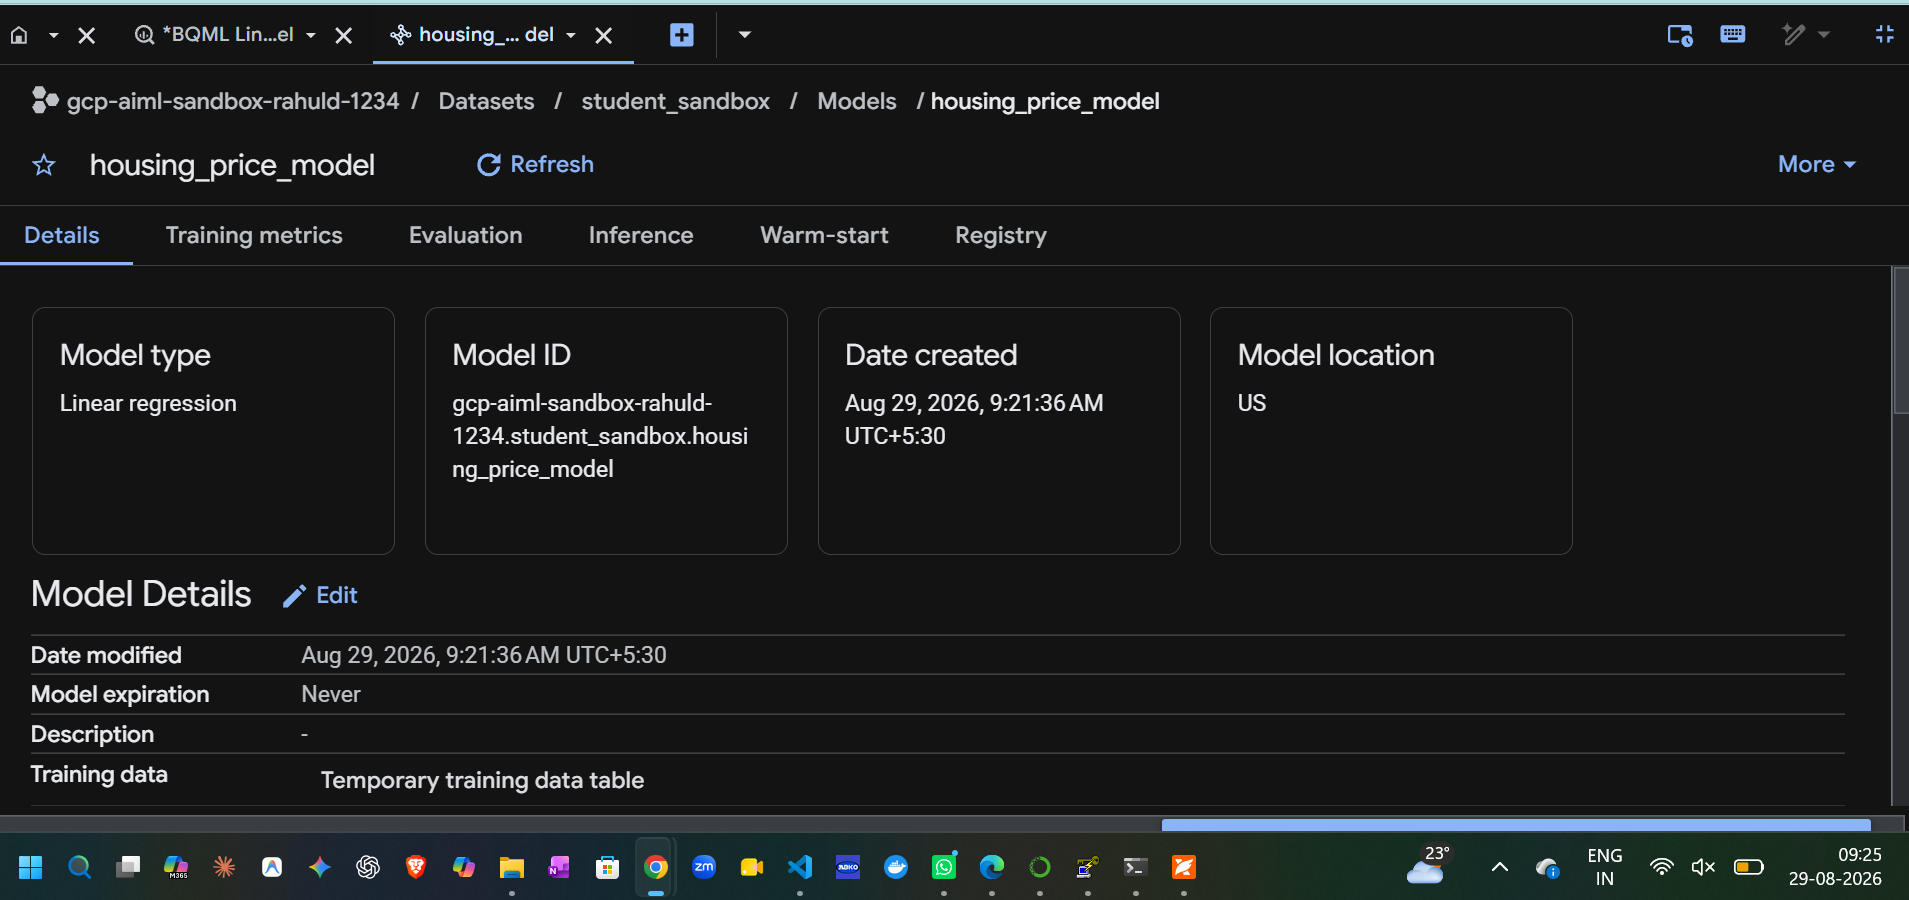

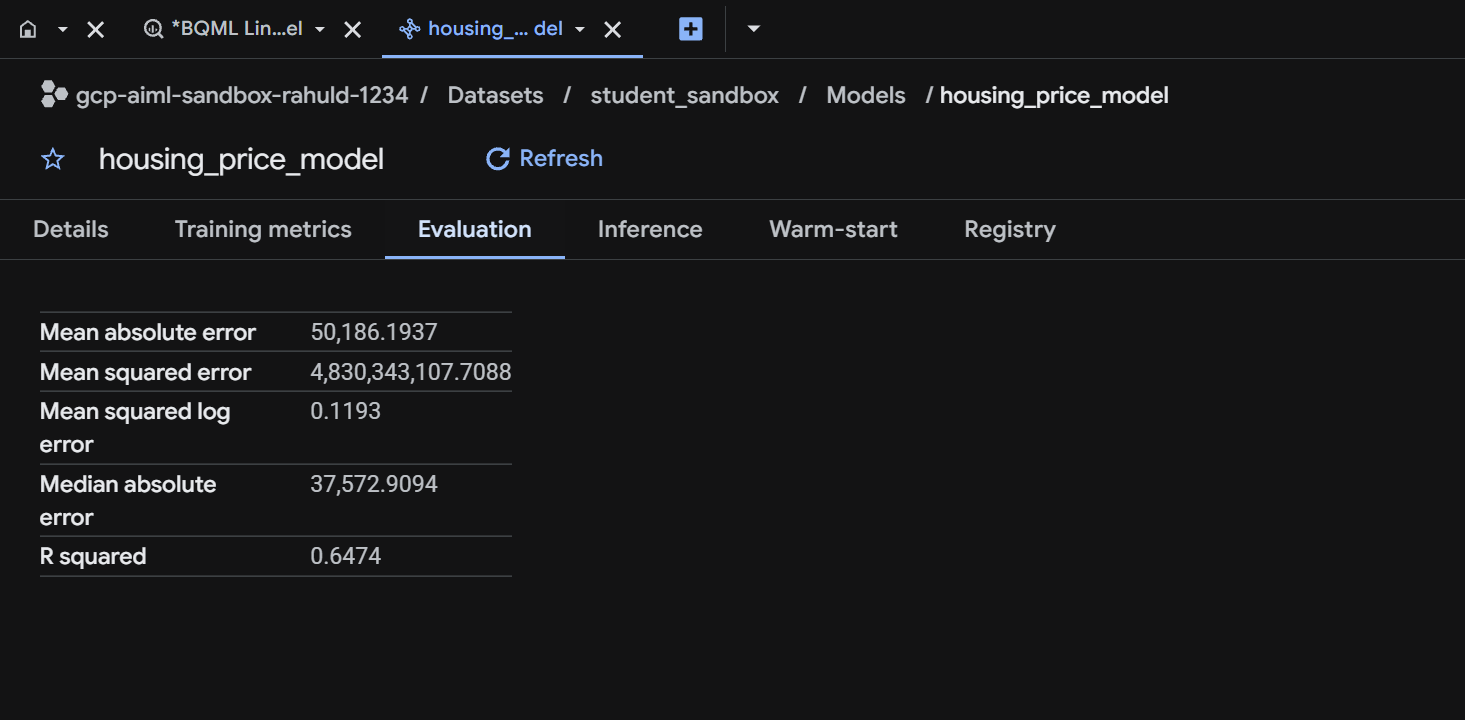

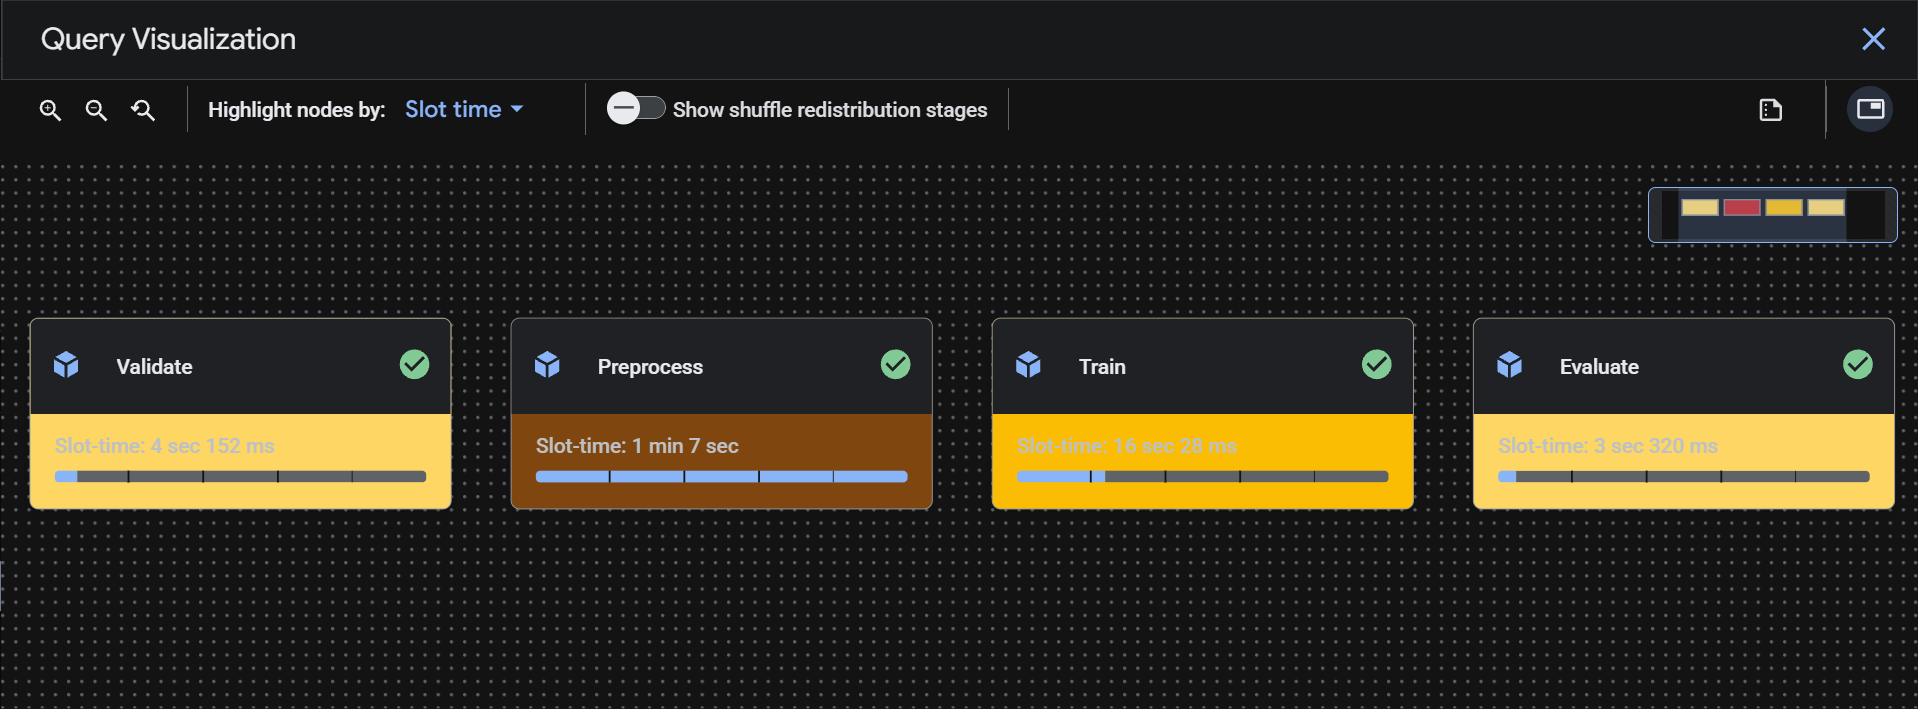

---
- **Step 4**: Evaluate Model Performance (R², MAE, RMSE) -> BQML returns MAE, MSE, RMSE, and R2 metrics instantly.
```sql
-- Evaluate the trained model
SELECT
  *
FROM
  ML.EVALUATE(MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.housing_price_model`);
```
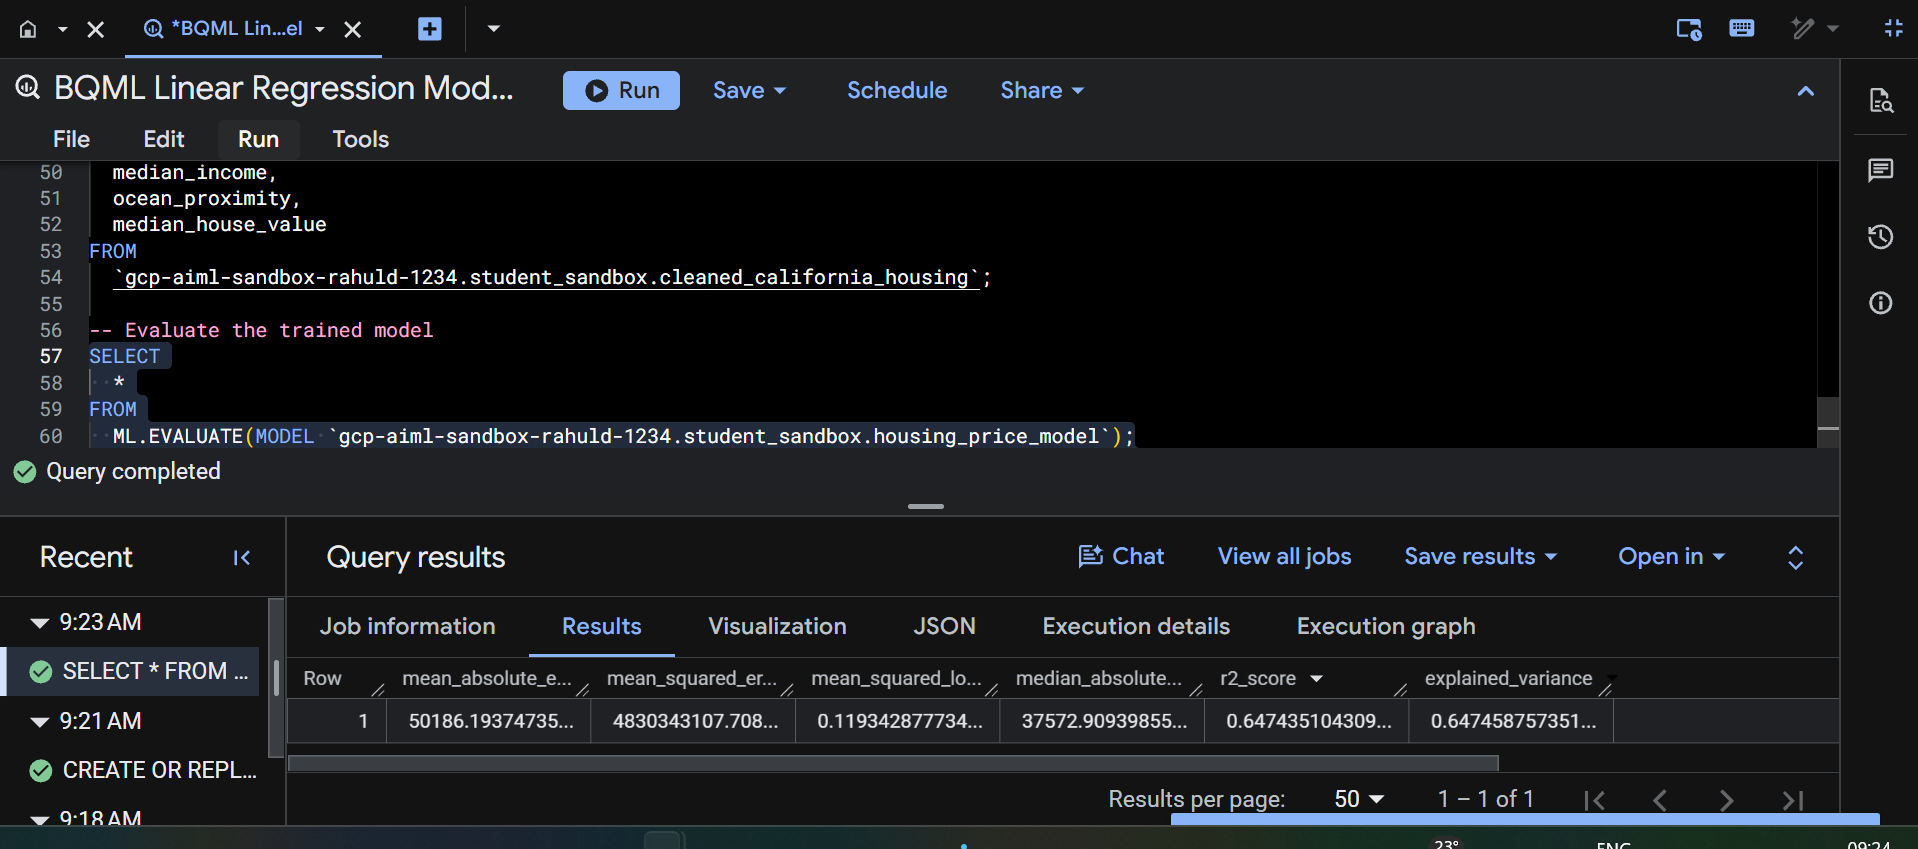

---

- **Step 5**: Check Feature Weights (Coefficients) -> This displays the feature weights (coefficients) and the intercept, showing you which features have the highest impact on house prices.
```sql
-- View weights/coefficients for each feature (like model.coef_ and model.intercept_ in Python)
SELECT
  processed_input,
  weight,
  category_weights
FROM
  ML.WEIGHTS(MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.housing_price_model`)
ORDER BY 
  ABS(weight) DESC;
```
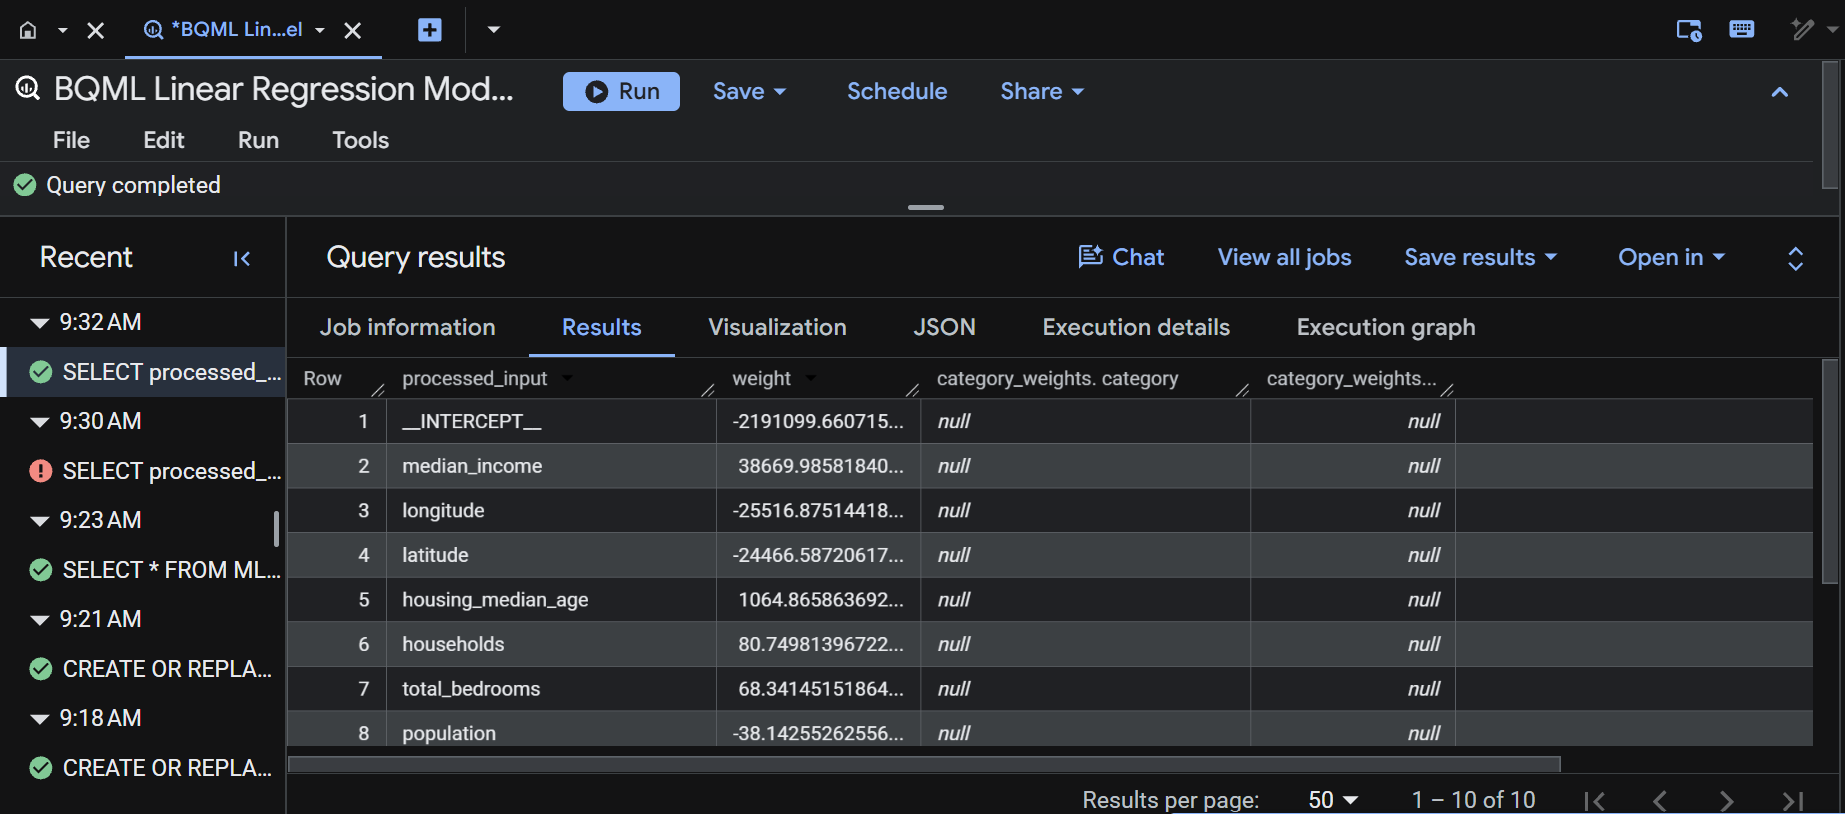

---
- **Step 6**: Generate House Price Predictions -> We provide the model with unseen features to predict the predicted_median_house_value.
```sql
-- Generate price predictions for some unseen houses
SELECT
  predicted_median_house_value,
  longitude,
  latitude,
  housing_median_age,
  total_rooms,
  total_bedrooms,
  population,
  households,
  median_income,
  ocean_proximity
FROM
  ML.PREDICT(
    MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.housing_price_model`,
    (
      -- Constructing unseen houses to test
      SELECT 
        -122.23 AS longitude, 37.88 AS latitude, 41.0 AS housing_median_age, 
        880.0 AS total_rooms, 129.0 AS total_bedrooms, 322.0 AS population, 
        126.0 AS households, 8.3 AS median_income, 'NEAR BAY' AS ocean_proximity
      UNION ALL
      SELECT 
        -118.25 AS longitude, 34.05 AS latitude, 20.0 AS housing_median_age, 
        1500.0 AS total_rooms, 350.0 AS total_bedrooms, 1200.0 AS population, 
        310.0 AS households, 3.5 AS median_income, 'INLAND' AS ocean_proximity
    )
  );
```
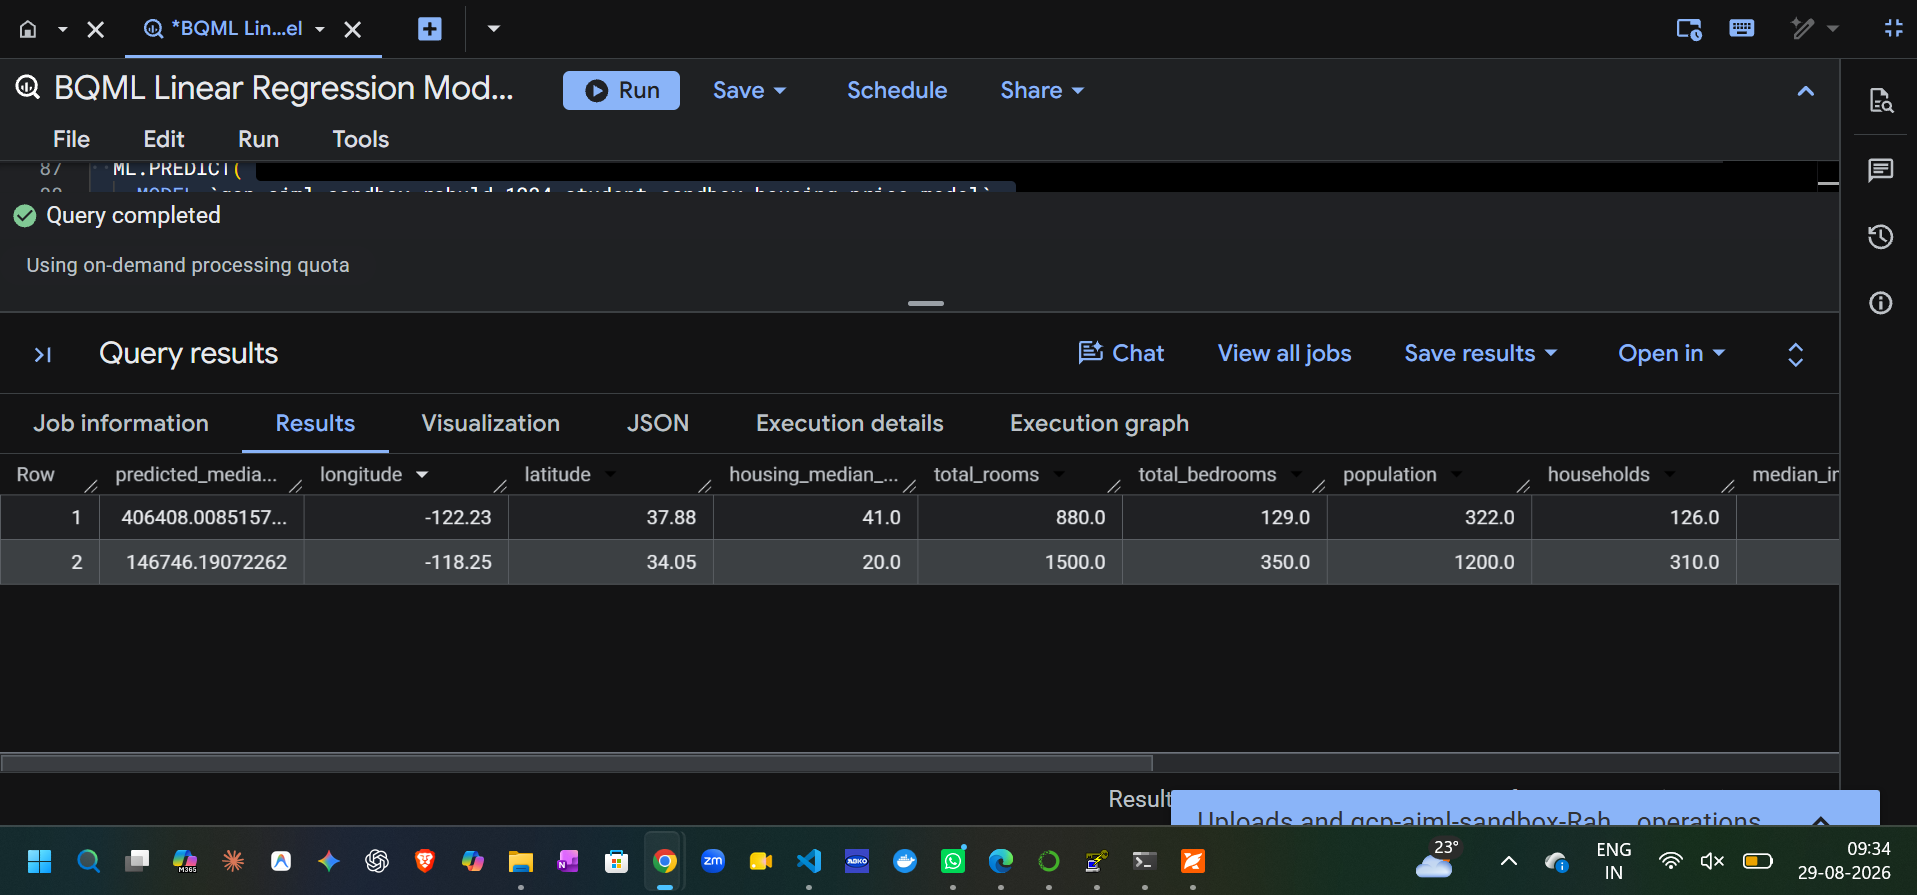

---
- **Step 7**: Cleanup Resources (Optional) -> Run this when you are completely finished with your lab work to clear out the datasets and tables.
```sql
-- Clean up all created resources
DROP MODEL IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox.housing_price_model`;
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox.cleaned_california_housing`;
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox.raw_california_housing`;
DROP SCHEMA IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox` CASCADE;
```
---